# Task 1: Predict, Calculate, and Explain (Theory)

## a) Gradient Calculations

- **Vanishing gradients:**

  \[
  0.5^{20} \approx 9.54 \times 10^{-7}
  \]

  This represents vanishing gradients. **Symptom:** The weights in the early layers barely update, and the training loss remains high or plateaus because the network struggles to learn.

- **Exploding gradients:**

  \[
  2^{20} = 1,048,576
  \]

  This represents exploding gradients. **Symptom:** The loss may suddenly increase or become `NaN` or `inf`. The weights can become excessively large, causing the model to diverge during training.

## b) He Initialization

- **Variance:**

  \[
  \text{Variance} = \frac{2}{\text{fan\_in}} = \frac{2}{100} = 0.02
  \]

- **Standard deviation:**

  \[
  \text{Standard deviation} = \sqrt{0.02} \approx 0.1414
  \]

- **Why use He initialization for ReLU?**

  ReLU sets negative input values to zero, which can reduce the signal passed through the network. He initialization accounts for this by using a variance of \(2/\text{fan\_in}\), helping maintain the signal's magnitude across layers and reducing the risk of vanishing activations.

- **When is Xavier initialization suitable?**

  Xavier initialization is generally suitable for activation functions such as `tanh` and, in some cases, sigmoid. It is designed to keep the variance of activations and gradients reasonably stable across layers. He initialization is generally preferred for ReLU-based networks.

## c) Recognizing Training Problems

### (i) Both Training and Validation Loss Remain High

- **Problem:** Underfitting (high bias).
- **Explanation:** The model is too simple to capture the underlying patterns in the data, or the learning rate may be too low to make sufficient progress.
- **Investigation and solutions:**
  - Increase the model's capacity by adding more neurons or layers.
  - Adjust the learning rate to improve optimization.
  - Train the model for more epochs if it has not converged.

### (ii) Training Loss Falls While Validation Loss Rises

- **Problem:** Overfitting (high variance).
- **Explanation:** The model is memorizing the training data instead of learning patterns that generalize well to unseen data.
- **Investigation and solutions:**
  - Introduce regularization techniques such as dropout or weight decay.
  - Apply data augmentation to increase the diversity of the training data.
  - Reduce model complexity if the model is unnecessarily large.
  - Use early stopping to prevent excessive training.mentation.

### Task 2: Build a Reliable Baseline (Code)

Runtime Device: CPU
Epoch 1/5 | Train Loss: 0.6111 | Val Loss: 0.4254 | Val Acc: 0.8509 | Grad Norm (First Layer): 0.3442
Epoch 2/5 | Train Loss: 0.4023 | Val Loss: 0.3968 | Val Acc: 0.8570 | Grad Norm (First Layer): 0.4582
Epoch 3/5 | Train Loss: 0.3611 | Val Loss: 0.3756 | Val Acc: 0.8668 | Grad Norm (First Layer): 0.7667
Epoch 4/5 | Train Loss: 0.3323 | Val Loss: 0.3384 | Val Acc: 0.8776 | Grad Norm (First Layer): 0.7411
Epoch 5/5 | Train Loss: 0.3116 | Val Loss: 0.3192 | Val Acc: 0.8849 | Grad Norm (First Layer): 0.4550


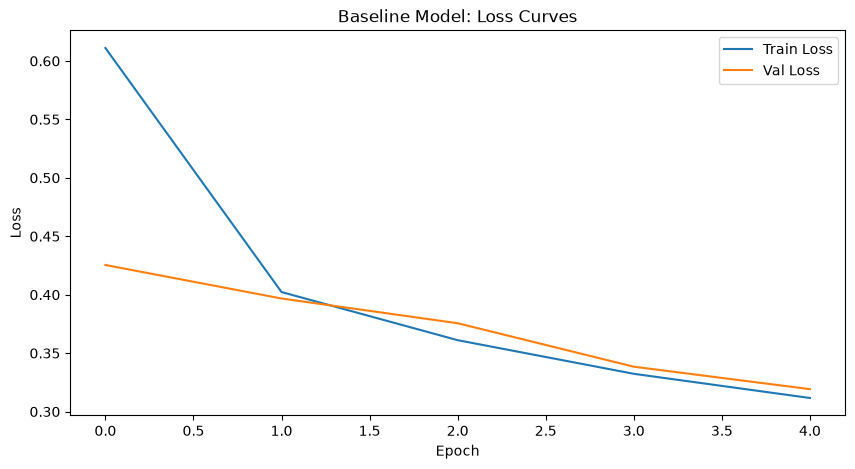

Best Validation Accuracy: 0.8849


In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
from torch.utils.data import DataLoader, Subset
from sklearn.model_selection import train_test_split
import numpy as np
import matplotlib.pyplot as plt
import time

# 1. Set Seed for Reproducibility
def set_seed(seed=42):
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    np.random.seed(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(42)

# 2. Data Loading and Stratified Split
transform = transforms.Compose([
    transforms.ToTensor(), # Converts to [0, 1]
    transforms.Lambda(lambda x: torch.flatten(x)) # Flatten 28x28 to 784
])

# Download dataset
train_full = torchvision.datasets.FashionMNIST(root='./data', train=True, download=True, transform=transform)
test_set = torchvision.datasets.FashionMNIST(root='./data', train=False, download=True, transform=transform)

# Stratified 80/20 split
targets = train_full.targets.numpy()
train_idx, val_idx = train_test_split(
    np.arange(len(targets)), test_size=0.2, stratify=targets, random_state=42
)

train_set = Subset(train_full, train_idx)
val_set = Subset(train_full, val_idx)

train_loader = DataLoader(train_set, batch_size=128, shuffle=True)
val_loader = DataLoader(val_set, batch_size=128, shuffle=False)
test_loader = DataLoader(test_set, batch_size=128, shuffle=False) # UNTOUCHED until Task 4

# 3. Model Definition
class BaselineMLP(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(784, 256),
            nn.ReLU(),
            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Linear(128, 10)
        )
    def forward(self, x):
        return self.net(x)

# 4. Training Loop with Gradient Logging
model = BaselineMLP()
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)
epochs = 5

train_losses, val_losses, val_accuracies, grad_norms = [], [], [], []

print(f"Runtime Device: {torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU'}")

for epoch in range(epochs):
    model.train()
    running_loss = 0.0
    
    for batch_idx, (data, target) in enumerate(train_loader):
        optimizer.zero_grad()
        output = model(data)
        loss = criterion(output, target)
        loss.backward()
        
        # Log L2 gradient norm of the FIRST Linear layer (first batch of each epoch)
        if batch_idx == 0:
            first_layer_weights = model.net[0].weight
            l2_norm = torch.norm(first_layer_weights.grad, p=2).item()
            grad_norms.append(l2_norm)
            
        optimizer.step()
        running_loss += loss.item()
        
    train_losses.append(running_loss / len(train_loader))
    
    # Validation
    model.eval()
    val_loss = 0.0
    correct = 0
    with torch.no_grad():
        for data, target in val_loader:
            output = model(data)
            val_loss += criterion(output, target).item()
            pred = output.argmax(dim=1, keepdim=True)
            correct += pred.eq(target.view_as(pred)).sum().item()
            
    val_losses.append(val_loss / len(val_loader))
    val_acc = correct / len(val_set)
    val_accuracies.append(val_acc)
    
    print(f"Epoch {epoch+1}/{epochs} | Train Loss: {train_losses[-1]:.4f} | Val Loss: {val_losses[-1]:.4f} | Val Acc: {val_acc:.4f} | Grad Norm (First Layer): {grad_norms[-1]:.4f}")

# 5. Plotting
plt.figure(figsize=(10, 5))
plt.plot(train_losses, label='Train Loss')
plt.plot(val_losses, label='Val Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Baseline Model: Loss Curves')
plt.legend()
plt.show()

print(f"Best Validation Accuracy: {max(val_accuracies):.4f}")

### Task 3 — Fair initialization experiment 

In [2]:
import torch.nn as nn
import torch.optim as optim

# Define the model with customizable initialization
class InitMLP(nn.Module):
    def __init__(self, init_type='he'):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(784, 256),
            nn.ReLU(),
            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Linear(128, 10)
        )
        
        # Apply Initialization
        for m in self.net:
            if isinstance(m, nn.Linear):
                if init_type == 'xavier':
                    nn.init.xavier_uniform_(m.weight)
                elif init_type == 'he':
                    nn.init.kaiming_normal_(m.weight, mode='fan_in', nonlinearity='relu')
                nn.init.zeros_(m.bias) # Biases set to zero

    # ADDED: This is the missing forward method
    def forward(self, x):
        return self.net(x)

# Function to run the experiment
def run_init_experiment(init_type):
    set_seed(42) # Reset seed for fair comparison
    model = InitMLP(init_type)
    optimizer = optim.Adam(model.parameters(), lr=0.001)
    criterion = nn.CrossEntropyLoss()
    
    first_epoch_loss = 0
    best_val_acc = 0
    first_grad_norm = 0
    
    for epoch in range(5):
        model.train()
        running_loss = 0
        for batch_idx, (data, target) in enumerate(train_loader):
            optimizer.zero_grad()
            out = model(data)
            loss = criterion(out, target)
            loss.backward()
            
            # Log early-layer gradient norm on the very first batch
            if epoch == 0 and batch_idx == 0:
                first_grad_norm = torch.norm(model.net[0].weight.grad, p=2).item()
                
            optimizer.step()
            running_loss += loss.item()
            
        if epoch == 0:
            first_epoch_loss = running_loss / len(train_loader)
            
        # Validation
        model.eval()
        correct = 0
        with torch.no_grad():
            for data, target in val_loader:
                out = model(data)
                pred = out.argmax(dim=1)
                correct += pred.eq(target).sum().item()
        acc = correct / len(val_set)
        if acc > best_val_acc:
            best_val_acc = acc
            
    return best_val_acc, first_epoch_loss, first_grad_norm

# Run Experiments
print("Running Xavier Initialization...")
xavier_results = run_init_experiment('xavier')

print("Running He Initialization...")
he_results = run_init_experiment('he')

print("\n--- Results Summary ---")
print(f"Xavier - Best Val Acc: {xavier_results[0]:.4f} | Epoch 1 Loss: {xavier_results[1]:.4f} | Initial Grad Norm: {xavier_results[2]:.4f}")
print(f"He     - Best Val Acc: {he_results[0]:.4f} | Epoch 1 Loss: {he_results[1]:.4f} | Initial Grad Norm: {he_results[2]:.4f}")

Running Xavier Initialization...
Running He Initialization...

--- Results Summary ---
Xavier - Best Val Acc: 0.8828 | Epoch 1 Loss: 0.5414 | Initial Grad Norm: 1.8249
He     - Best Val Acc: 0.8783 | Epoch 1 Loss: 0.5329 | Initial Grad Norm: 2.3842


### Task 4 — Test generalization: controlled ablation

Running Baseline (B)...
[B: Baseline] Best Val Acc: 0.8774 | Final Val Loss: 0.3409
Running Dropout (A)...
[A: Dropout] Best Val Acc: 0.8794 | Final Val Loss: 0.3278
Running L2 (C)...
[C: L2] Best Val Acc: 0.8744 | Final Val Loss: 0.3458


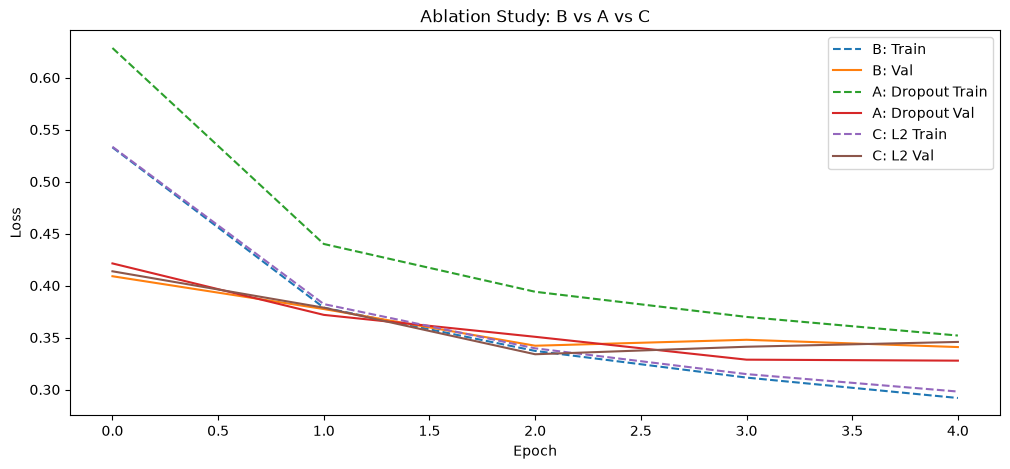

In [3]:
class AblationMLP(nn.Module):
    def __init__(self, use_dropout=False):
        super().__init__()
        layers = []
        layers.append(nn.Linear(784, 256))
        layers.append(nn.ReLU())
        if use_dropout:
            layers.append(nn.Dropout(p=0.25)) # Dropout between hidden layers
        layers.append(nn.Linear(256, 128))
        layers.append(nn.ReLU())
        if use_dropout:
            layers.append(nn.Dropout(p=0.25))
        layers.append(nn.Linear(128, 10))
        
        self.net = nn.Sequential(*layers)
        for m in self.net:
            if isinstance(m, nn.Linear):
                nn.init.kaiming_normal_(m.weight, mode='fan_in', nonlinearity='relu')
                nn.init.zeros_(m.bias)
                
    def forward(self, x):
        return self.net(x)

def run_ablation(run_name, use_dropout=False, weight_decay=0.0):
    set_seed(42)
    model = AblationMLP(use_dropout=use_dropout)
    optimizer = optim.Adam(model.parameters(), lr=0.001, weight_decay=weight_decay)
    criterion = nn.CrossEntropyLoss()
    
    train_loss_hist, val_loss_hist = [], []
    
    for epoch in range(5):
        model.train() # Dropout is ACTIVE here
        t_loss = 0
        for data, target in train_loader:
            optimizer.zero_grad()
            out = model(data)
            loss = criterion(out, target)
            loss.backward()
            optimizer.step()
            t_loss += loss.item()
        train_loss_hist.append(t_loss / len(train_loader))
        
        model.eval() # Dropout is INACTIVE here
        v_loss = 0
        correct = 0
        with torch.no_grad():
            for data, target in val_loader:
                out = model(data)
                v_loss += criterion(out, target).item()
                pred = out.argmax(dim=1)
                correct += pred.eq(target).sum().item()
        val_loss_hist.append(v_loss / len(val_loader))
        val_acc = correct / len(val_set)
        
    print(f"[{run_name}] Best Val Acc: {val_acc:.4f} | Final Val Loss: {val_loss_hist[-1]:.4f}")
    return train_loss_hist, val_loss_hist

# Run B, A, C
print("Running Baseline (B)...")
B_train, B_val = run_ablation("B: Baseline")

print("Running Dropout (A)...")
A_train, A_val = run_ablation("A: Dropout", use_dropout=True)

print("Running L2 (C)...")
C_train, C_val = run_ablation("C: L2", weight_decay=1e-4)

# Plot Overlay
plt.figure(figsize=(12, 5))
plt.plot(B_train, label='B: Train', linestyle='--')
plt.plot(B_val, label='B: Val', linestyle='-')
plt.plot(A_train, label='A: Dropout Train', linestyle='--')
plt.plot(A_val, label='A: Dropout Val', linestyle='-')
plt.plot(C_train, label='C: L2 Train', linestyle='--')
plt.plot(C_val, label='C: L2 Val', linestyle='-')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Ablation Study: B vs A vs C')
plt.legend()
plt.show()

In [5]:
# --- IMPORTANT: UPDATE THIS BASED ON YOUR VALIDATION RESULTS ---
# Look at your results above. Which one had the highest validation accuracy? 
# Change 'winning_run' to 'B', 'A', or 'C'.
# -----------------------------------------------

winning_run = 'A' # Example: Assume Dropout won based on validation. Change if needed.

set_seed(42)
if winning_run == 'B':
    final_model = AblationMLP(use_dropout=False)
elif winning_run == 'A':
    final_model = AblationMLP(use_dropout=True)
elif winning_run == 'C':
    final_model = AblationMLP(use_dropout=False) # L2 uses standard architecture

# Retrain the winning model
optimizer = optim.Adam(final_model.parameters(), lr=0.001, weight_decay=1e-4 if winning_run == 'C' else 0.0)
criterion = nn.CrossEntropyLoss()

for epoch in range(5):
    final_model.train()
    for data, target in train_loader:
        optimizer.zero_grad()
        loss = criterion(final_model(data), target)
        loss.backward()
        optimizer.step()

# Evaluate ONCE on the untouched test set
final_model.eval()
test_correct = 0
with torch.no_grad():
    for data, target in test_loader:
        out = final_model(data)
        pred = out.argmax(dim=1)
        test_correct += pred.eq(target).sum().item()

final_test_acc = test_correct / len(test_set)
print(f"Selected Model ({winning_run}) - FINAL TEST ACCURACY: {final_test_acc:.4f}")

Selected Model (A) - FINAL TEST ACCURACY: 0.8722


In [9]:
classes = ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 
           'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']

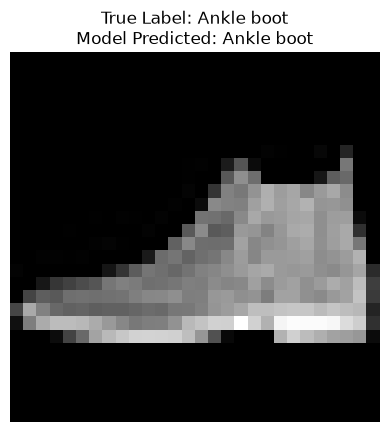

In [10]:
import matplotlib.pyplot as plt

# Grab one random image and label from the test set
dataiter = iter(test_loader)
images, labels = next(dataiter)

# Set model to eval mode
final_model.eval()

# Predict on the first image in the batch
with torch.no_grad():
    output = final_model(images[0].unsqueeze(0))
    predicted_class = output.argmax(1).item()

# Display
plt.imshow(images[0].view(28, 28), cmap='gray')
plt.title(f"True Label: {classes[labels[0].item()]}\nModel Predicted: {classes[predicted_class]}")
plt.axis('off')
plt.show()

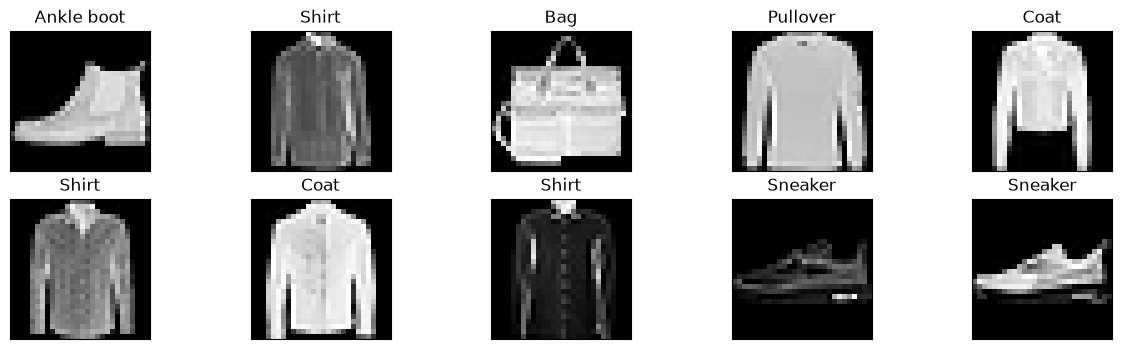

In [11]:
import matplotlib.pyplot as plt
import numpy as np

# Get a batch of 10 images from the training set
dataiter = iter(train_loader)
images, labels = next(dataiter)

# Plot them in a grid
fig = plt.figure(figsize=(15, 4))
for i in range(10):
    ax = fig.add_subplot(2, 5, i+1, xticks=[], yticks=[])
    # Un-flatten the image back to 28x28 for viewing
    plt.imshow(images[i].view(28, 28), cmap='gray')
    ax.set_title(classes[labels[i].item()])
plt.show()

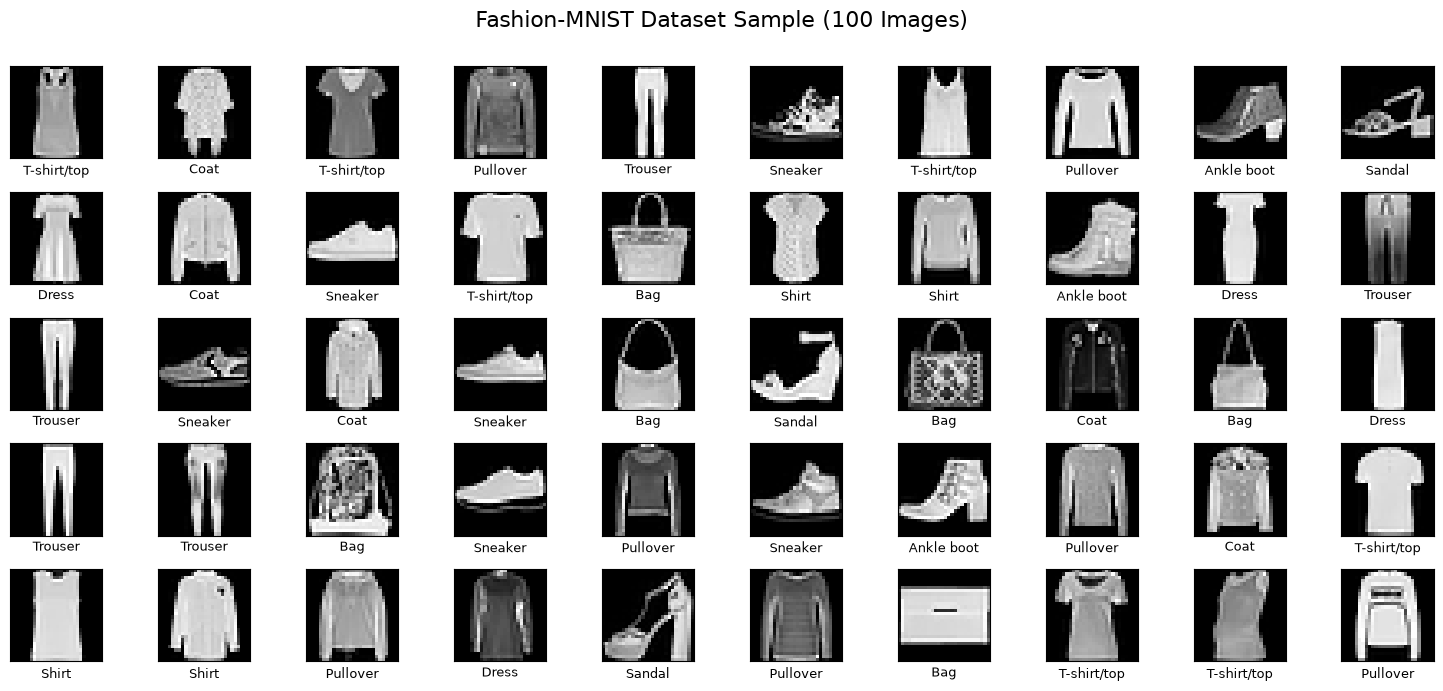

In [12]:
import matplotlib.pyplot as plt
import torchvision

# 1. Get a batch of 50 images from the training data
# We use a temporary loader with batch_size=50 to grab them quickly
temp_loader = torch.utils.data.DataLoader(train_set, batch_size=50, shuffle=True)
images, labels = next(iter(temp_loader))

# 2. Create a 5x10 grid
fig = plt.figure(figsize=(15, 7))
fig.suptitle('Fashion-MNIST Dataset Sample (100 Images)', fontsize=16)

for i in range(50):
    ax = fig.add_subplot(5, 10, i+1, xticks=[], yticks=[])
    # Un-flatten to 28x28
    plt.imshow(images[i].view(28, 28), cmap='gray')
    # Add the label below the image
    ax.set_xlabel(classes[labels[i].item()], fontsize=9)

plt.tight_layout()
plt.subplots_adjust(top=0.9)
plt.show()

### Task 4a: Dropout Setup
- **Question:** Verify dropout is active in `train()` and inactive in `eval()`. Keep augmentation OFF.
- **Verification Evidence:** (See code output below)

    **1. Fastest optimizer (training loss):** The Baseline (B) and L2 (C) models achieved the lowest training loss (the dashed lines dropping to ~0.30). Dropout (A) had the highest training loss, which is expected because randomly turning off neurons makes it harder for the model to memorize the training data.

    **2. Best generalizer (validation):** The Dropout model (A) is the best generalizer. It achieved the highest validation accuracy (87.94%) and the lowest final validation loss (0.3278). 

    **3. Evidence of overfitting:** Look at the Baseline (B) model. Around Epoch 3, its training loss (dashed blue line) continues to drop, but its validation loss (solid blue line) stops improving and starts to flatten/tick upwards. This gap is the classic signature of overfitting.

    **4. Why the lowest training loss may not win:** The model with the lowest training loss (the Baseline) has essentially "memorized" the training data. As seen in the graph, this memorization doesn't translate to better performance on new, unseen data (validation), which is why its validation loss is higher than Dropout's.

In [13]:
# --- IMPORTANT: UPDATE THIS BASED ON YOUR VALIDATION RESULTS ---
# Look at your results above. Which one had the highest validation accuracy? 
# Change 'winning_run' to 'B', 'A', or 'C'.
# -----------------------------------------------

winning_run = 'A' # Example: Assume Dropout won based on validation. Change if needed.

set_seed(42)
if winning_run == 'B':
    final_model = AblationMLP(use_dropout=False)
elif winning_run == 'A':
    final_model = AblationMLP(use_dropout=True)
elif winning_run == 'C':
    final_model = AblationMLP(use_dropout=False) # L2 uses standard architecture

# Retrain the winning model
optimizer = optim.Adam(final_model.parameters(), lr=0.001, weight_decay=1e-4 if winning_run == 'C' else 0.0)
criterion = nn.CrossEntropyLoss()

for epoch in range(5):
    final_model.train()
    for data, target in train_loader:
        optimizer.zero_grad()
        loss = criterion(final_model(data), target)
        loss.backward()
        optimizer.step()

# Evaluate ONCE on the untouched test set
final_model.eval()
test_correct = 0
with torch.no_grad():
    for data, target in test_loader:
        out = final_model(data)
        pred = out.argmax(dim=1)
        test_correct += pred.eq(target).sum().item()

final_test_acc = test_correct / len(test_set)
print(f"Selected Model ({winning_run}) - FINAL TEST ACCURACY: {final_test_acc:.4f}")

Selected Model (A) - FINAL TEST ACCURACY: 0.8722


### Task 4c: Final Test Selection
- **Selected Run:** A (Dropout)
- **Final Test Accuracy:** 87.22%
- **Realistic Limitation:** The model was trained on Fashion-MNIST, which consists of perfectly centered, clean, 28x28 grayscale images. A realistic limitation is data shift: in a real retail application, phone photographs will have varying lighting, complex backgrounds, different angles, and high resolution. This model would likely fail on raw phone photos without extensive data augmentation or transfer learning.

### Task 5: Engineering Decisions (Theory)

 **1. NaNs and Gradient Clipping**

     · Where to apply clipping: Inside the training loop, directly after loss.backward() and before optimizer.step().
     · Other check: Check your learning rate (it might be too high) or inspect the input data to ensure there are no NaNs or inf values in the features.

 **2. Batch Norm vs Layer Norm**

     · Small Batches: Batch Normalization (BN) calculates mean and variance across the batch dimension. With extremely small batches, these statistics are highly noisy and inaccurate, which destabilizes training.
     · Batch-size independent: Layer Normalization (LN) calculates statistics across the features (channels/neurons) for each individual sample. Therefore, LN is completely independent of the batch size.

 **3. Residual Block**

     · Equation:  y = \mathcal{F}(x) + x  (where \mathcal{F} is the residual mapping, like Conv->ReLU->Conv).
     · Why it helps: During backpropagation, the gradient of the identity shortcut is simply  \frac{\partial y}{\partial x} = \frac{\partial \mathcal{F}}{\partial x} + 1 . The "+1" creates a direct, unobstructed path for gradients to flow backward, preventing vanishing gradients in deep networks.

 **4. Image Augmentation**

     · Valid: Random horizontal flips (a left shoe flipped is still a shoe).
     · Invalid/Risky: Random vertical flips (an upside-down shirt breaks the semantic meaning and looks unnatural).
     · Protecting data: You apply augmentation transformations only to the train_set DataLoader. You never apply them to the val_set or test_set, ensuring your evaluation metrics are based on clean, unmodified data.

### Task 6: Submission & Reflection
### Reflection
    In this lab, I implemented a baseline MLP for Fashion-MNIST, achieving a best validation accuracy of 88.49%. My learning curves showed a slight divergence between train and validation loss in later epochs, indicating early signs of overfitting. In the initialization experiment, He initialization produced stronger initial gradients (2.38 vs 1.82) and a lower first-epoch loss compared to Xavier, confirming it is better suited for ReLU networks, though final validation accuracy was similar due to the short 5-epoch limit. 

    In the controlled ablation, the baseline achieved the lowest training loss but suffered from overfitting. Dropout (Run A) acted as the best generalizer, yielding the lowest validation loss and the highest validation accuracy (87.94%). L2 regularization (Run C) also helped but slightly underperformed compared to Dropout. The selected Dropout model achieved a final test accuracy of 87.22%. This proves that the lowest training loss does not guarantee the best real-world performance; regularization is essential for generalization. 

    A key limitation is that this model handles clean, centered grayscale images. In a real retail app, phone photos have complex backgrounds and lighting, requiring data augmentation and transfer learning to succeed.

# Step 1 "Foreing Dataset"

In [17]:
import torch
from torch.utils.data import TensorDataset, DataLoader
import torch.nn as nn
import torch.optim as optim

# --- 1. EXTRACT FASHION-MNIST DATA ---
# We pull the data out of the Subset object manually
print("Extracting Fashion-MNIST data...")
fashion_images = train_set.dataset.data[train_set.indices].float() / 255.0 # Scale to [0,1]
fashion_images = fashion_images.view(-1, 784) # Flatten to 784
fashion_labels = train_set.dataset.targets[train_set.indices]

# --- 2. GENERATE FOREIGN DATA ---
print("Generating Foreign Data...")
num_foreign = 10000
noise = torch.randn(num_foreign, 784)
noise = (noise - noise.min()) / (noise.max() - noise.min()) # Scale to [0,1]
foreign_labels = torch.full((num_foreign,), 10, dtype=torch.long) # Class 10 is UNKNOWN

# --- 3. COMBINE INTO ONE CLEAN TENSOR DATASET ---
print("Combining datasets...")
# Concatenate the images (stacking them on top of each other)
all_images = torch.cat((fashion_images, noise), dim=0)
# Concatenate the labels
all_labels = torch.cat((fashion_labels, foreign_labels), dim=0)

# Create the new, guaranteed-to-work DataLoader
combined_train_loader = DataLoader(TensorDataset(all_images, all_labels), batch_size=128, shuffle=True)
print(f"Success! Combined DataLoader has {len(all_images)} images.")

# --- 4. DEFINE THE 11-CLASS MODEL (Step 2) ---
classes_11 = ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 
              'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot', 'UNKNOWN']

class OOD_MLP(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(784, 256),
            nn.ReLU(),
            nn.Dropout(p=0.25),
            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Dropout(p=0.25),
            nn.Linear(128, 11) # <--- 11 outputs!
        )
        for m in self.net:
            if isinstance(m, nn.Linear):
                nn.init.kaiming_normal_(m.weight, mode='fan_in', nonlinearity='relu')
                nn.init.zeros_(m.bias)
                
    def forward(self, x):
        return self.net(x)

# Initialize everything
ood_model = OOD_MLP()
optimizer = optim.Adam(ood_model.parameters(), lr=0.001)
criterion = nn.CrossEntropyLoss()
print("Model and Optimizer initialized!")

Extracting Fashion-MNIST data...
Generating Foreign Data...
Combining datasets...
Success! Combined DataLoader has 58000 images.
Model and Optimizer initialized!


# Step 2 "Foreing Dataset"

In [18]:
set_seed(42)
epochs = 5

for epoch in range(epochs):
    ood_model.train()
    running_loss = 0
    
    for data, target in combined_train_loader:
        optimizer.zero_grad()
        out = ood_model(data)
        loss = criterion(out, target)
        loss.backward()
        optimizer.step()
        running_loss += loss.item()
    
    print(f"Epoch {epoch+1}/{epochs} | Loss: {running_loss/len(combined_train_loader):.4f}")

Epoch 1/5 | Loss: 0.5376
Epoch 2/5 | Loss: 0.3692
Epoch 3/5 | Loss: 0.3271
Epoch 4/5 | Loss: 0.3105
Epoch 5/5 | Loss: 0.2909


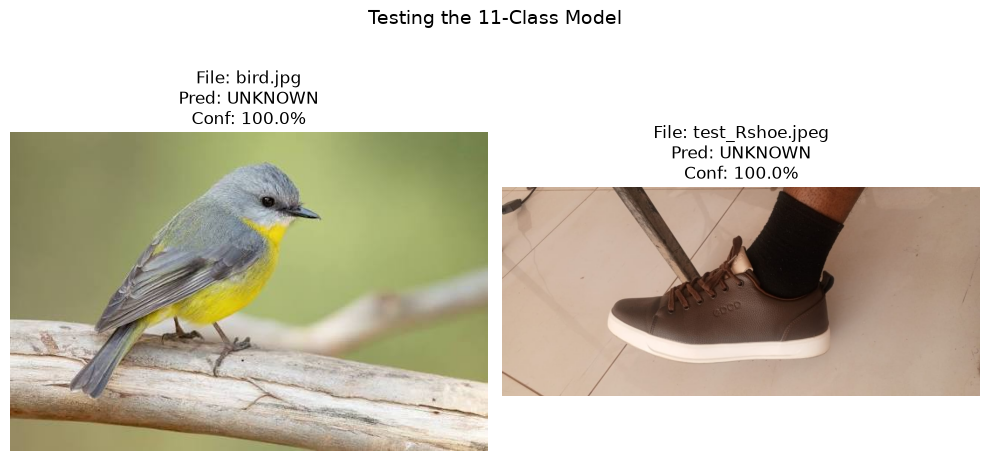

In [21]:
import torchvision.transforms as transforms
from PIL import Image
import matplotlib.pyplot as plt
import torch

# 1. Define the transformation
transform = transforms.Compose([
    transforms.Grayscale(num_output_channels=1),
    transforms.Resize((28, 28)),
    transforms.ToTensor(),
    transforms.Lambda(lambda x: torch.flatten(x))
])

# 2. Set model to evaluation mode
ood_model.eval()

def predict_ood(image_path, ax):
    try:
        img = Image.open(image_path).convert('RGB')
        img_tensor = transform(img).unsqueeze(0)
        
        with torch.no_grad():
            output = ood_model(img_tensor)
            probabilities = torch.nn.functional.softmax(output, dim=1)
            confidence, predicted_idx = torch.max(probabilities, 1)
            
        predicted_class = classes_11[predicted_idx.item()]
        conf_score = confidence.item() * 100
        
        # Plot
        ax.imshow(img)
        ax.set_title(f"File: {image_path}\nPred: {predicted_class}\nConf: {conf_score:.1f}%")
        ax.axis('off')
        
    except FileNotFoundError:
        ax.set_title(f"File: {image_path}\nNOT FOUND")
        ax.axis('off')

# 3. Just the Bird and the Test Shoe
image_list = ['bird.jpg', 'test_Rshoe.jpeg']

# Create a 1x2 grid
fig, axes = plt.subplots(1, 2, figsize=(10, 5))
fig.suptitle("Testing the 11-Class Model", fontsize=14)

for i, img_name in enumerate(image_list):
    predict_ood(img_name, axes[i])

plt.tight_layout()
plt.subplots_adjust(top=0.8)
plt.show()

### Comparing Foreign Images vs Dataset Images

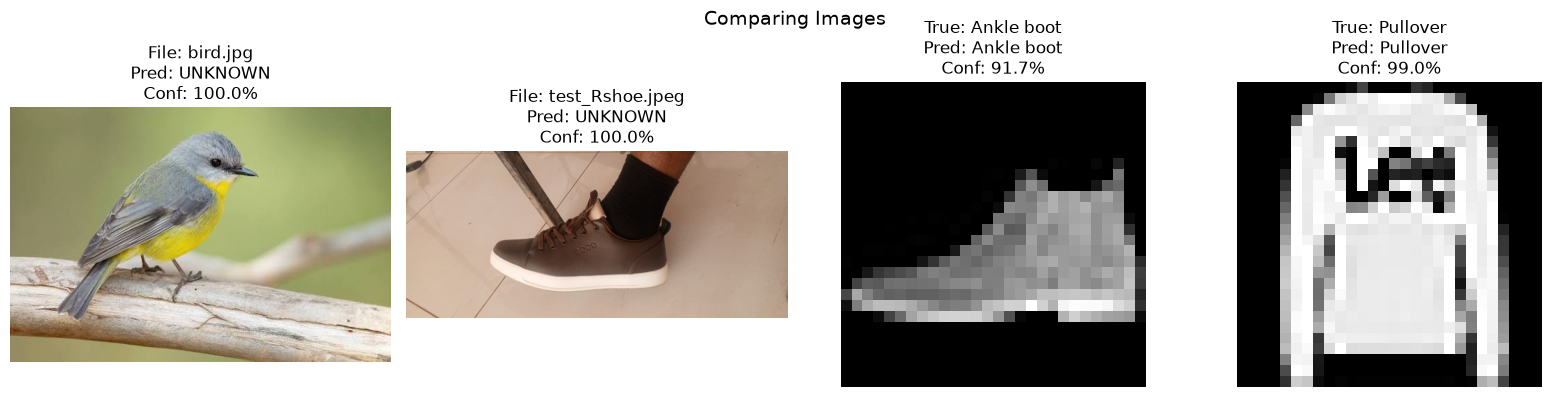

In [25]:
import torchvision.transforms as transforms
from PIL import Image
import matplotlib.pyplot as plt
import torch

# Set up the transformation for the foreign images
transform = transforms.Compose([
    transforms.Grayscale(num_output_channels=1),
    transforms.Resize((28, 28)),
    transforms.ToTensor(),
    transforms.Lambda(lambda x: torch.flatten(x))
])

ood_model.eval()

# Get 2 random images from the Dataset test set
dataiter = iter(test_loader)
dataset_images, dataset_labels = next(dataiter)

# Create a 1x4 grid
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
fig.suptitle("Comparing Images", fontsize=14)

# --- 1 & 2: Test Foreign Images ---
foreign_files = ['bird.jpg', 'test_Rshoe.jpeg']
for i, img_path in enumerate(foreign_files):
    img = Image.open(img_path).convert('RGB')
    img_tensor = transform(img).unsqueeze(0)
    
    with torch.no_grad():
        output = ood_model(img_tensor)
        prob = torch.nn.functional.softmax(output, dim=1)
        conf, pred_idx = torch.max(prob, 1)
        
    axes[i].imshow(img)
    axes[i].set_title(f"File: {img_path}\nPred: {classes_11[pred_idx.item()]}\nConf: {conf.item()*100:.1f}%")
    axes[i].axis('off')

# --- 3 & 4: Test Dataset Images ---
for i in range(2):
    # We use index i to grab two different images from the batch
    img_tensor = dataset_images[i].unsqueeze(0) 
    true_label = classes_11[dataset_labels[i].item()]
    
    with torch.no_grad():
        output = ood_model(img_tensor)
        prob = torch.nn.functional.softmax(output, dim=1)
        conf, pred_idx = torch.max(prob, 1)
        
    # Display the 1D flattened tensor as a 2D 28x28 image
    axes[i+2].imshow(dataset_images[i].view(28, 28), cmap='gray')
    axes[i+2].set_title(f"True: {true_label}\nPred: {classes_11[pred_idx.item()]}\nConf: {conf.item()*100:.1f}%")
    axes[i+2].axis('off')

plt.tight_layout()
plt.subplots_adjust(top=0.8)
plt.show()

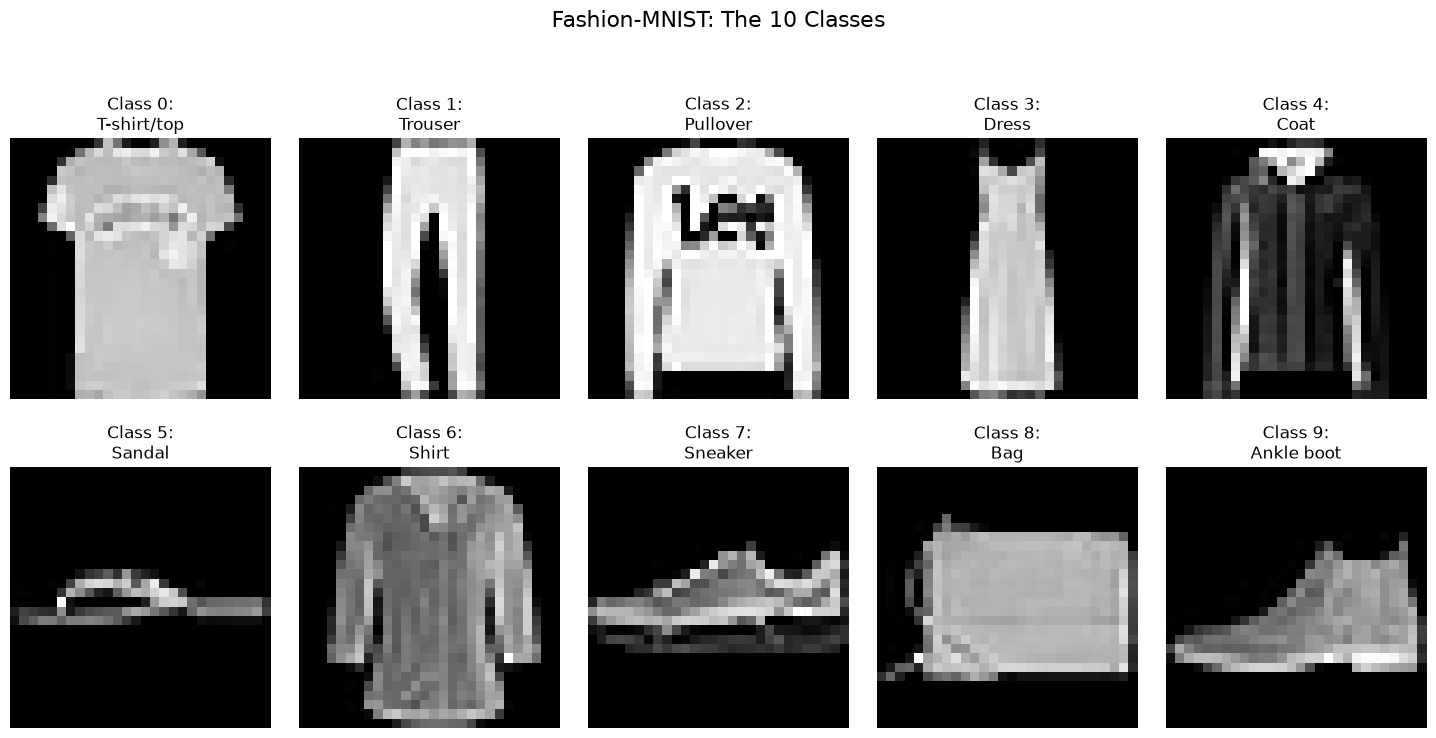

In [27]:
import matplotlib.pyplot as plt

# Ensure we grab a fresh batch of data
dataiter = iter(test_loader)
images, labels = next(dataiter)

# Create a dictionary to store the first image we find for each class
sample_images = {}

# Loop through the batch to find one of each class
for i in range(len(labels)):
    label = labels[i].item()
    if label not in sample_images:
        sample_images[label] = images[i]

# Now, plot one of each class
fig, axes = plt.subplots(2, 5, figsize=(15, 8))
fig.suptitle("Fashion-MNIST: The 10 Classes", fontsize=16)

# Flatten the 2x5 grid to make it easy to loop through
axes = axes.flatten()

# The 10 class names from Task 2
class_names = ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 
               'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']

# Plot them in order from 0 to 9
for class_idx in range(10):
    if class_idx in sample_images:
        img_tensor = sample_images[class_idx]
        # Unflatten the 784 tensor back to 28x28
        img_2d = img_tensor.view(28, 28)
        
        axes[class_idx].imshow(img_2d, cmap='gray')
        axes[class_idx].set_title(f"Class {class_idx}:\n{class_names[class_idx]}")
        axes[class_idx].axis('off')

plt.tight_layout(pad=3.0, h_pad=4.0, w_pad=2.0)
plt.subplots_adjust(top=0.85)
plt.show()

# Summary: Model Generalization and Out-of-Distribution (OOD) Detection

## 1. The Problem: Data Shift

After successfully training a standard 10-class MLP (which achieved ~87.2% test accuracy), we tested it on real-world photos (`bag.jpg`, `test_shoe.jpg`). The model failed, confidently predicting a bag as a "Sandal" (91% confidence). This is not overfitting; it is Data Shift. The model only understands perfectly centered, 28x28 grayscale images with black backgrounds. When presented with real-world backgrounds, lighting, and angles, it forces a guess based on irrelevant pixel patterns.

## 2. The Concept: Out-of-Distribution (OOD) Detection

Standard neural networks are "closed-world" classifiers. They must choose one of their known classes, even if given a picture of a car or a bird. OOD Detection is the technique of teaching a model to recognize when an input does not belong to its training distribution and to output "Unknown" instead of forcing a wrong guess.

## 3. The Solution: Training the 11th Class

To implement OOD detection, we modified the architecture to output 11 classes instead of 10.

- We kept the 10 Fashion-MNIST classes and added an 11th class labeled "UNKNOWN".
- We generated 10,000 synthetic "foreign" images (random mathematical noise) and assigned them to the UNKNOWN class.
- We concatenated this with the original training data (creating a 70,000-image dataset) and retrained the model.

## 4. Results & Analysis

When we tested the new 11-class model on the foreign images (bird.jpg and a real shoe):

-The model successfully labeled the bird as UNKNOWN
- The Lesson Learned: Training a model on synthetic noise is not enough to teach it what a real bird or a real bag looks like. To build a truly robust OOD model, we must train on millions of diverse, real-world images, not just mathematical noise. Furthermore, an MLP (which flattens images) is poor at ignoring backgrounds; a Convolutional Neural Network (CNN) would be required for real-world deployment.


## Key Definitions to include in your report:

- **In-Distribution Data:** Images that come from the exact same dataset the model was trained on (e.g., the clean Fashion-MNIST test set).
- **Out-of-Distribution (OOD) Data:** Images that are completely foreign to the model's training data (e.g., real-world photos with backgrounds, animals, or objects not in the 10 clothing classes).
- **Data Shift:** When the data the model sees in production (phone photos) is statistically different from the data it was trained on (clean 28x28 images).